In [32]:
import random
import warnings
from pathlib import Path
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from skimage import color, filters, measure

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Portable dataset path resolution
DEFAULT_PATH = Path(r"C:\Users\george\Desktop\stage1_train")
DATA_DIR = DEFAULT_PATH if DEFAULT_PATH.exists() else Path("./stage1_train")

# Automatically unzip the dataset if found as a zip file
if not DATA_DIR.exists() and Path("/content/stage1_train.zip").exists():
    print("Extracting stage1_train.zip...")
    with zipfile.ZipFile("/content/stage1_train.zip", "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

assert DATA_DIR.exists(), f"Dataset directory not found at {DATA_DIR}"

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

print(f"Environment ready | Dataset path: {DATA_DIR.resolve()}")

Environment ready | Dataset path: /content/stage1_train


In [33]:
def load_image_and_masks(sample_dir: Path):
    """Loads an RGB image and merges its non-overlapping instance masks."""
    img_path = next((sample_dir / "images").glob("*.png"))
    img_rgb = np.array(Image.open(img_path).convert("RGB"))

    mask_paths = sorted((sample_dir / "masks").glob("*.png"))
    h, w = img_rgb.shape[:2]
    instance_mask = np.zeros((h, w), dtype=np.int32)
    overlap_pixels = 0

    for idx, m_path in enumerate(mask_paths, start=1):
        m = np.array(Image.open(m_path)) > 0
        if m.shape != (h, w):
            raise ValueError(f"Shape mismatch in {sample_dir.name}: {m.shape} vs {(h, w)}")
        overlap_pixels += int(np.sum((instance_mask > 0) & m))
        instance_mask = np.where(m, idx, instance_mask)

    return img_rgb, instance_mask, len(mask_paths), overlap_pixels


def classify_background_polarity(gray_float: np.ndarray) -> str:
    """
    Determines whether background is 'dark' or 'bright' using both a 10px border
    sample and Otsu foreground-area majority (nuclei occupy <50% of image area).
    """
    h, w = gray_float.shape
    pad = min(10, h // 4, w // 4)
    border_pixels = np.concatenate([
        gray_float[:pad, :].ravel(),
        gray_float[-pad:, :].ravel(),
        gray_float[:, :pad].ravel(),
        gray_float[:, -pad:].ravel(),
    ])
    border_med = float(np.median(border_pixels))

    thresh = filters.threshold_otsu(gray_float)
    bright_area_ratio = float(np.mean(gray_float > thresh))

    # Bright background if border is bright OR bright pixels dominate (>55% area)
    if border_med > 0.5 or bright_area_ratio > 0.55:
        return "bright"
    return "dark"


def analyze_dataset_integrity(data_dir: Path) -> pd.DataFrame:
    records = []
    sample_dirs = sorted([d for d in data_dir.iterdir() if d.is_dir()])

    for s_dir in sample_dirs:
        img_files = list((s_dir / "images").glob("*.png"))
        mask_files = list((s_dir / "masks").glob("*.png"))

        if not img_files or not mask_files:
            records.append({"image_id": s_dir.name, "valid": False})
            continue

        img_rgb, inst_mask, n_masks, overlaps = load_image_and_masks(s_dir)
        gray = color.rgb2gray(img_rgb)  # Luminance-weighted [0, 1] float
        h, w = gray.shape

        is_color = not (
            np.array_equal(img_rgb[:, :, 0], img_rgb[:, :, 1])
            and np.array_equal(img_rgb[:, :, 1], img_rgb[:, :, 2])
        )
        bg_type = classify_background_polarity(gray)

        props = measure.regionprops(inst_mask)
        areas = [p.area for p in props]

        records.append({
            "image_id": s_dir.name,
            "valid": True,
            "height": h,
            "width": w,
            "resolution": f"{h}x{w}",
            "is_color": is_color,
            "bg_type": bg_type,
            "mean_intensity": float(gray.mean()),
            "std_intensity": float(gray.std()),
            "n_nuclei": n_masks,
            "overlap_pixels": overlaps,
            "fg_ratio": float(np.mean(inst_mask > 0)),
            "median_nucleus_area": float(np.median(areas)) if areas else 0.0,
            "p5_area": float(np.percentile(areas, 5)) if areas else 0.0,
            "p95_area": float(np.percentile(areas, 95)) if areas else 0.0,
        })

    return pd.DataFrame(records)


df = analyze_dataset_integrity(DATA_DIR)
assert df["valid"].all(), "Some samples failed integrity checks!"
assert df["overlap_pixels"].sum() == 0, "Instance mask overlaps detected!"
print(f"Verified {len(df)} samples | 0 missing files | 0 mask overlaps.")

Verified 670 samples | 0 missing files | 0 mask overlaps.


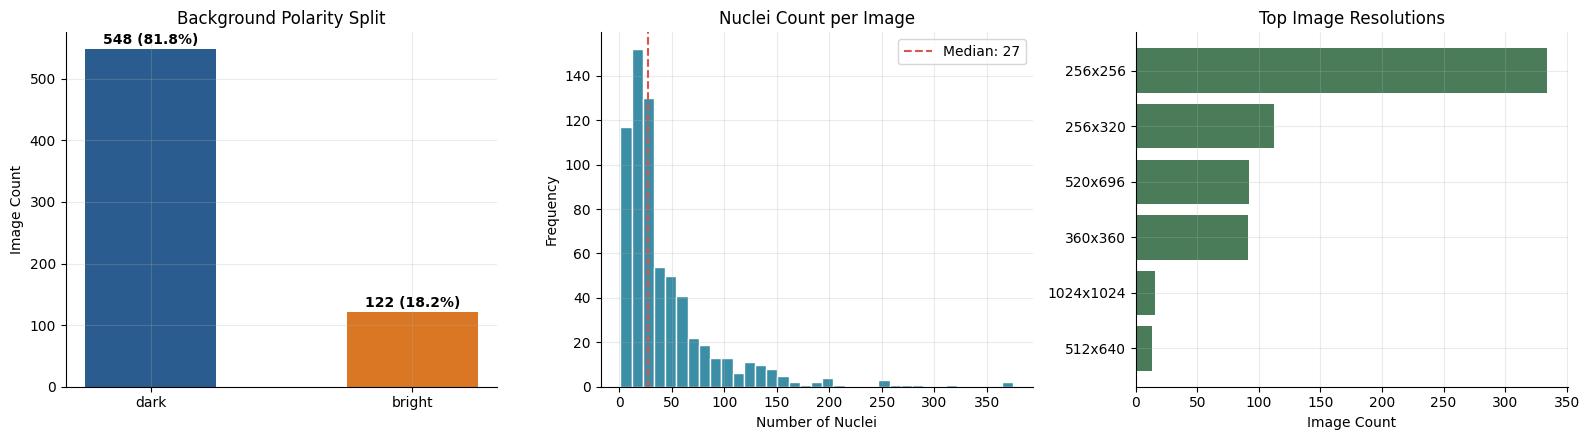

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Background Polarity Split
bg_counts = df["bg_type"].value_counts()
axes[0].bar(bg_counts.index, bg_counts.values, color=["#2b5c8f", "#d97724"], width=0.5)
axes[0].set_title("Background Polarity Split")
axes[0].set_ylabel("Image Count")
for idx, val in enumerate(bg_counts.values):
    axes[0].text(idx, val + 8, f"{val} ({val/len(df):.1%})", ha="center", fontweight="bold")

# 2. Nuclei Count Distribution
axes[1].hist(df["n_nuclei"], bins=35, color="#3b8ea5", edgecolor="white")
axes[1].axvline(df["n_nuclei"].median(), color="#d9534f", linestyle="--",
                label=f"Median: {df['n_nuclei'].median():.0f}")
axes[1].set_title("Nuclei Count per Image")
axes[1].set_xlabel("Number of Nuclei")
axes[1].set_ylabel("Frequency")
axes[1].legend()

# 3. Top Image Resolutions
top_res = df["resolution"].value_counts().head(6)
axes[2].barh(top_res.index[::-1], top_res.values[::-1], color="#4a7c59")
axes[2].set_title("Top Image Resolutions")
axes[2].set_xlabel("Image Count")

plt.tight_layout()
plt.show()

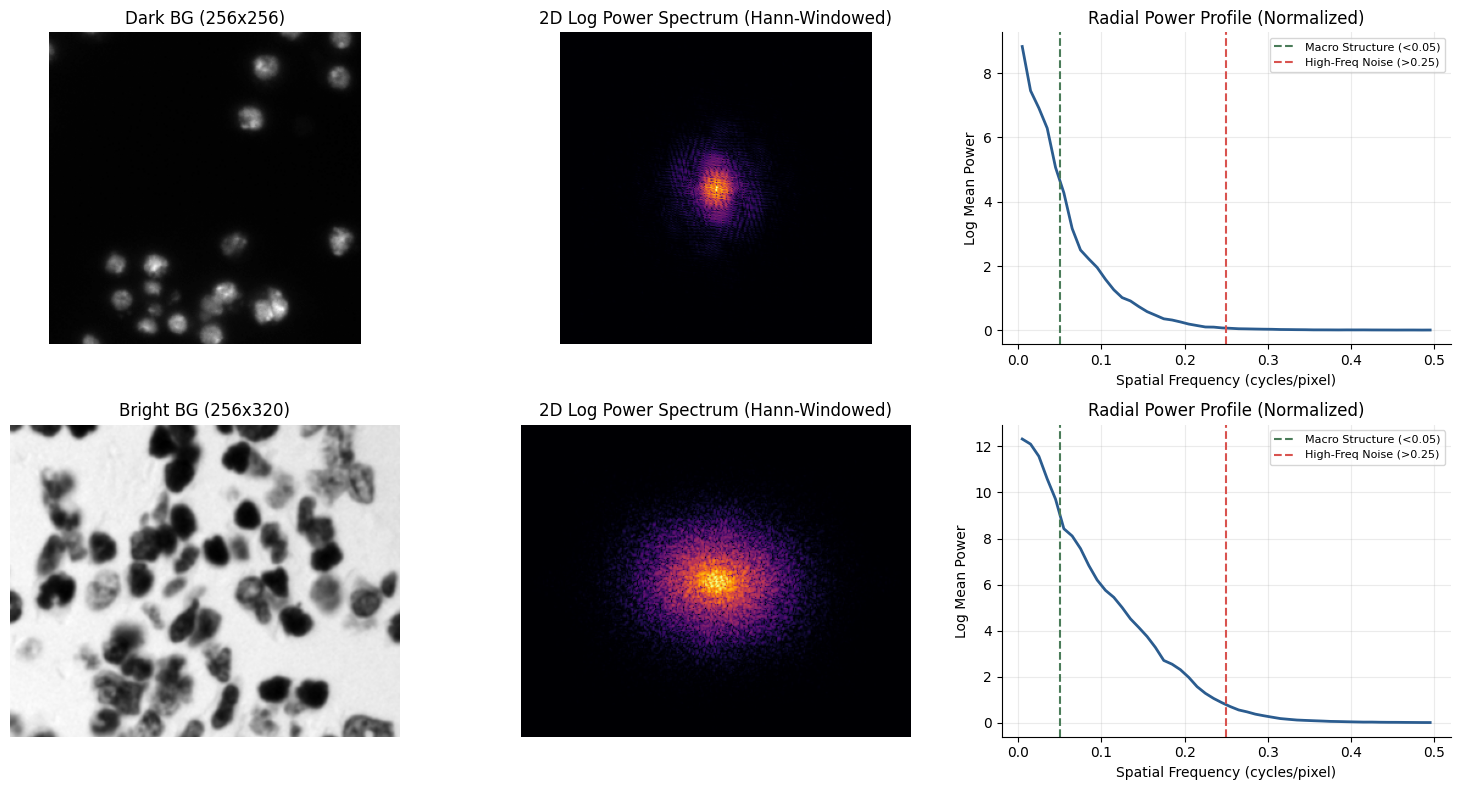

In [35]:
def compute_radial_power_spectrum(gray_float: np.ndarray):
    """Computes zero-mean, Hann-windowed 2D FFT and normalized radial power profile."""
    h, w = gray_float.shape
    centered = gray_float - gray_float.mean()
    window = np.outer(np.hanning(h), np.hanning(w))
    windowed = centered * window

    f_shift = np.fft.fftshift(np.fft.fft2(windowed))
    power_2d = np.abs(f_shift) ** 2

    # Normalized frequency coordinates in cycles/pixel [-0.5, 0.5]
    fy = np.fft.fftshift(np.fft.fftfreq(h))
    fx = np.fft.fftshift(np.fft.fftfreq(w))
    fx_grid, fy_grid = np.meshgrid(fx, fy)
    freq_radius = np.sqrt(fx_grid**2 + fy_grid**2)

    bins = np.linspace(0.0, 0.5, 51)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    radial_profile = np.zeros(len(bin_centers))

    for i in range(len(bin_centers)):
        mask = (freq_radius >= bins[i]) & (freq_radius < bins[i + 1])
        radial_profile[i] = power_2d[mask].mean() if np.any(mask) else np.nan

    return np.log1p(power_2d), bin_centers, np.log1p(radial_profile)


sample_dark = df[df["bg_type"] == "dark"].iloc[0]["image_id"]
sample_bright = df[df["bg_type"] == "bright"].iloc[0]["image_id"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row_idx, (label, img_id) in enumerate([("Dark BG", sample_dark), ("Bright BG", sample_bright)]):
    img_rgb, _, _, _ = load_image_and_masks(DATA_DIR / img_id)
    gray = color.rgb2gray(img_rgb)
    log_spec, freqs, rad_prof = compute_radial_power_spectrum(gray)

    axes[row_idx, 0].imshow(gray, cmap="gray")
    axes[row_idx, 0].set_title(f"{label} ({gray.shape[0]}x{gray.shape[1]})")
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(log_spec, cmap="inferno")
    axes[row_idx, 1].set_title("2D Log Power Spectrum (Hann-Windowed)")
    axes[row_idx, 1].axis("off")

    axes[row_idx, 2].plot(freqs, rad_prof, color="#2b5c8f", linewidth=2)
    axes[row_idx, 2].axvline(0.05, color="#4a7c59", linestyle="--", label="Macro Structure (<0.05)")
    axes[row_idx, 2].axvline(0.25, color="#d9534f", linestyle="--", label="High-Freq Noise (>0.25)")
    axes[row_idx, 2].set_title("Radial Power Profile (Normalized)")
    axes[row_idx, 2].set_xlabel("Spatial Frequency (cycles/pixel)")
    axes[row_idx, 2].set_ylabel("Log Mean Power")
    axes[row_idx, 2].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [36]:
from scipy import ndimage
from skimage import color, exposure, feature, filters, measure, morphology, segmentation


def preprocess_image(img_rgb: np.ndarray, bg_type: str) -> np.ndarray:
    """
    Modality & polarity normalization with gentle denoising and mild CLAHE
    (low clip_limit prevents amplifying dark-background sensor noise).
    """
    is_color = not (
        np.array_equal(img_rgb[:, :, 0], img_rgb[:, :, 1])
        and np.array_equal(img_rgb[:, :, 1], img_rgb[:, :, 2])
    )
    if is_color and bg_type == "bright":
        # Green channel gives highest contrast for H&E purple/pink nuclei stains
        gray = img_rgb[:, :, 1].astype(np.float64) / 255.0
    else:
        gray = color.rgb2gray(img_rgb)

    if bg_type == "bright":
        gray = 1.0 - gray

    # Suppress high-frequency sensor grain
    denoised = filters.gaussian(gray, sigma=1.2, preserve_range=True)

    # Mild CLAHE boosts dim nuclei without amplifying dark-background noise
    enhanced = exposure.equalize_adapthist(denoised, clip_limit=0.008)
    return enhanced

In [37]:
def segment_nuclei_watershed(enhanced: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Scale-aware distance-transform Watershed that adapts peak distance
    and minimum object size to the actual nuclei scale inside each image.
    """
    # 1. Otsu threshold + morphological cleanup
    thresh = filters.threshold_otsu(enhanced)
    binary = enhanced > thresh

    # Scale minimum debris size to image resolution (~0.02% of image area, min 15px)
    min_area = max(15, int(0.0002 * binary.size))
    binary = ndimage.binary_fill_holes(binary)
    binary = morphology.remove_small_objects(binary, min_size=min_area)
    binary = morphology.binary_opening(binary, morphology.disk(1))

    if not np.any(binary):
        return binary, np.zeros_like(binary, dtype=np.int32)

    # 2. Estimate typical nucleus radius in this specific image
    initial_labels = measure.label(binary)
    props = measure.regionprops(initial_labels)
    median_equiv_radius = np.median([p.equivalent_diameter / 2.0 for p in props])

    # Adaptive peak spacing: ~65% of median nucleus radius (clamped to [6, 22] px)
    adaptive_min_dist = int(np.clip(0.65 * median_equiv_radius, 6, 22))
    smooth_sigma = max(1.5, 0.25 * adaptive_min_dist)

    # 3. Distance transform + smoothed peaks
    distance = ndimage.distance_transform_edt(binary)
    distance_smooth = filters.gaussian(distance, sigma=smooth_sigma, preserve_range=True)

    coords = feature.peak_local_max(
        distance_smooth,
        min_distance=adaptive_min_dist,
        labels=binary,
    )
    marker_mask = np.zeros(distance.shape, dtype=bool)
    marker_mask[tuple(coords.T)] = True
    markers = measure.label(marker_mask)

    if markers.max() == 0:
        markers = initial_labels

    # 4. Watershed split + cleanup
    instance_labels = segmentation.watershed(-distance_smooth, markers, mask=binary)
    instance_labels = morphology.remove_small_objects(instance_labels, min_size=min_area)
    instance_labels = (
        measure.label(instance_labels > 0)
        if instance_labels.max() == 0
        else segmentation.relabel_sequential(instance_labels)[0]
    )

    return binary, instance_labels

In [39]:
def compute_dsb_map(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    true_ids = np.unique(y_true)
    true_ids = true_ids[true_ids != 0]
    pred_ids = np.unique(y_pred)
    pred_ids = pred_ids[pred_ids != 0]

    n_true, n_pred = len(true_ids), len(pred_ids)
    if n_true == 0 and n_pred == 0:
        return 1.0
    if n_true == 0 or n_pred == 0:
        return 0.0

    _, true_inv = np.unique(y_true, return_inverse=True)
    true_seq = true_inv.reshape(y_true.shape)
    _, pred_inv = np.unique(y_pred, return_inverse=True)
    pred_seq = pred_inv.reshape(y_pred.shape)

    intersection = np.histogram2d(
        true_seq.ravel(),
        pred_seq.ravel(),
        bins=(n_true + 1, n_pred + 1),
    )[0][1:, 1:]

    area_true = np.histogram(true_seq, bins=range(1, n_true + 2))[0][:, None]
    area_pred = np.histogram(pred_seq, bins=range(1, n_pred + 2))[0][None, :]

    union = area_true + area_pred - intersection
    iou_matrix = np.where(union > 0, intersection / union, 0.0)

    thresholds = np.arange(0.50, 0.96, 0.05)
    precisions = []
    for t in thresholds:
        matches = iou_matrix > t
        tp = np.sum(np.any(matches, axis=1))
        fp = n_pred - np.sum(np.any(matches, axis=0))
        fn = n_true - tp
        precisions.append(tp / (tp + fp + fn))

    return float(np.mean(precisions))


def compute_semantic_dice(y_true_bin: np.ndarray, y_pred_bin: np.ndarray) -> float:
    inter = np.logical_and(y_true_bin, y_pred_bin).sum()
    denom = y_true_bin.sum() + y_pred_bin.sum()
    return float(2.0 * inter / denom) if denom > 0 else 1.0


def evaluate_phase2(df_meta: pd.DataFrame, data_dir: Path) -> pd.DataFrame:
    p2_maps, p2_dices, p2_counts = [], [], []

    for _, row in df_meta.iterrows():
        img_rgb, y_true, _, _ = load_image_and_masks(data_dir / row["image_id"])
        enhanced = preprocess_image(img_rgb, row["bg_type"])
        pred_bin, pred_inst = segment_nuclei_watershed(enhanced)

        p2_maps.append(compute_dsb_map(y_true, pred_inst))
        p2_dices.append(compute_semantic_dice(y_true > 0, pred_bin))
        p2_counts.append(int(pred_inst.max()))

    df_meta["phase2_map"] = p2_maps
    df_meta["phase2_dice"] = p2_dices
    df_meta["phase2_n_nuclei"] = p2_counts
    return df_meta


df = evaluate_phase2(df, DATA_DIR)

p1_candidates = [c for c in df.columns if "map" in c.lower() and "phase2" not in c.lower()]
baseline_col = p1_candidates[0]

print("=" * 70)
print("PHASE 2 BENCHMARK COMPARISON (DSB 2018 Instance mAP @ IoU 0.50:0.95)")
print("=" * 70)
print(f"Phase 1 — Polarity-Aware Otsu mAP    : {df[baseline_col].mean():.4f}")
print(f"Phase 2 — CLAHE + Watershed mAP      : {df['phase2_map'].mean():.4f}  ({df['phase2_map'].mean() - df[baseline_col].mean():+.4f})")
print(f"Phase 2 — Semantic Foreground Dice   : {df['phase2_dice'].mean():.4f}")
print("-" * 70)
for bg in ["dark", "bright"]:
    sub = df[df["bg_type"] == bg]
    print(
        f"[{bg.upper():6s} BG | n={len(sub):3d}] "
        f"P1 mAP: {sub[baseline_col].mean():.4f} -> "
        f"P2 mAP: {sub['phase2_map'].mean():.4f} "
        f"({sub['phase2_map'].mean() - sub[baseline_col].mean():+.4f})"
    )
print("=" * 70)

PHASE 2 BENCHMARK COMPARISON (DSB 2018 Instance mAP @ IoU 0.50:0.95)
Phase 1 — Polarity-Aware Otsu mAP    : 0.4027
Phase 2 — CLAHE + Watershed mAP      : 0.4335  (+0.0309)
Phase 2 — Semantic Foreground Dice   : 0.8617
----------------------------------------------------------------------
[DARK   BG | n=548] P1 mAP: 0.4578 -> P2 mAP: 0.4849 (+0.0271)
[BRIGHT BG | n=122] P1 mAP: 0.1549 -> P2 mAP: 0.2026 (+0.0477)


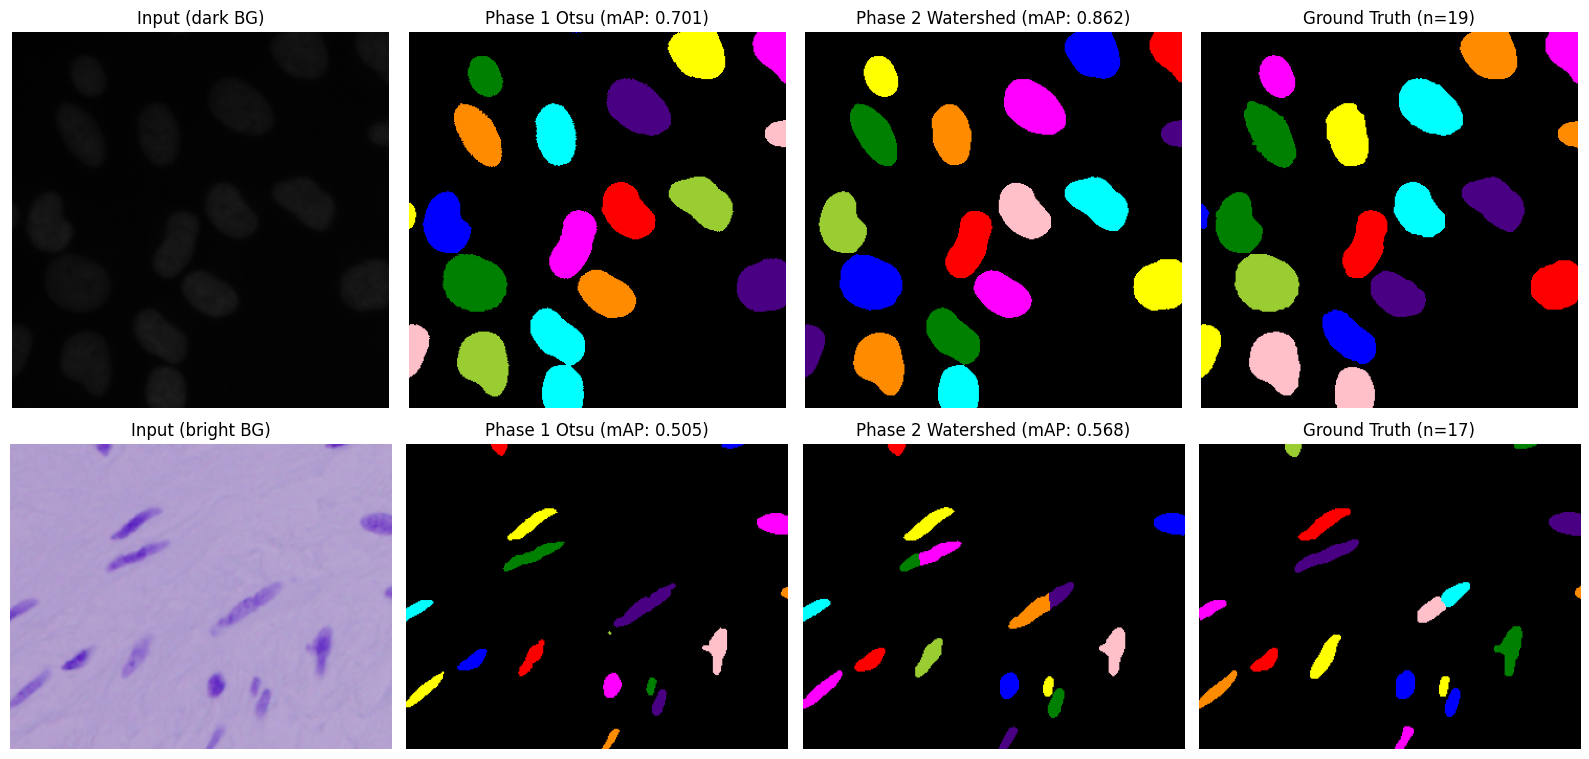

In [40]:
def visualize_phase2_comparison(df_meta: pd.DataFrame, data_dir: Path, base_col: str):
    dark_sample = df_meta[df_meta["bg_type"] == "dark"].sort_values(
        by="phase2_map", ascending=False
    ).iloc[5]
    bright_sample = df_meta[df_meta["bg_type"] == "bright"].sort_values(
        by="phase2_map", ascending=False
    ).iloc[2]

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    for row_idx, row in enumerate([dark_sample, bright_sample]):
        img_rgb, y_true, _, _ = load_image_and_masks(data_dir / row["image_id"])
        gray = color.rgb2gray(img_rgb)

        # Phase 1 prediction
        t1 = filters.threshold_otsu(gray)
        p1_bin = (gray < t1) if row["bg_type"] == "bright" else (gray > t1)
        p1_inst = measure.label(p1_bin)

        # Phase 2 prediction
        enhanced = preprocess_image(img_rgb, row["bg_type"])
        _, p2_inst = segment_nuclei_watershed(enhanced)

        axes[row_idx, 0].imshow(img_rgb)
        axes[row_idx, 0].set_title(f"Input ({row['bg_type']} BG)")

        axes[row_idx, 1].imshow(color.label2rgb(p1_inst, bg_label=0))
        axes[row_idx, 1].set_title(f"Phase 1 Otsu (mAP: {row[base_col]:.3f})")

        axes[row_idx, 2].imshow(color.label2rgb(p2_inst, bg_label=0))
        axes[row_idx, 2].set_title(f"Phase 2 Watershed (mAP: {row['phase2_map']:.3f})")

        axes[row_idx, 3].imshow(color.label2rgb(y_true, bg_label=0))
        axes[row_idx, 3].set_title(f"Ground Truth (n={row['n_nuclei']})")

        for col_idx in range(4):
            axes[row_idx, col_idx].axis("off")

    plt.tight_layout()
    plt.show()


visualize_phase2_comparison(df, DATA_DIR, baseline_col)